<a href="https://colab.research.google.com/github/mrsaeedalharbl-ux/Automated-Lab-Monitor/blob/main/Chemical_Engineering_%26_Computational_AI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chemical Engineering & Computational AI Project
## AI-Driven Pseudoternary Phase Diagram Mapping & Formulation Optimization

---

### Project Overview
Microemulsions are thermodynamically stable, isotropically clear colloidal dispersions consisting of oil, water, surfactant, and co-surfactant. Unlike conventional macroemulsions, their formation is spontaneous and strictly governed by phase equilibria principles.

This project deploys a computational framework using **Python in Google Colab** to map pseudoternary phase diagrams. By algorithmically predicting thermodynamic stability regimes (Winsor domains), this digital methodology eliminates tedious experimental trial-and-error titration trials, providing a fast screening platform for pharmaceutical and cosmetic nano-formulations.

---

### Theoretical Background & Pseudoternary Components
Colloidal phase behavior is defined by the Gibbs Phase Rule ($F = C - P + 2$). In this pseudoternary system, formulation ingredients are categorized into three thermodynamic entities:

1. **Aqueous Phase (Water - 100%):** The polar phase consisting of purified water, electrolytes, and hydrophilic active compounds.
2. **Oil Phase (100%):** The non-polar hydrophobic phase composed of lipids, triglycerides, and lipophilic ingredients.
3. **Surfactant / Co-surfactant Mixture (100%):** An optimized amphiphilic blend that lowers oil-water interfacial tension to ultra-low levels ($\approx 10^{-3} \text{ mN/m}$).

---

### Computational Workflow
* **Coordinate Conversion:** Transforms barycentric ternary fractions into two-dimensional Cartesian plane coordinates $(x, y)$.
* **Boundary Definition:** Outlines the equilateral Gibbs triangle representing total system composition.
* **Phase Classification:** Distinguishes unstable multi-phase emulsions from single-phase optimal microemulsion domains.

---
**Participating Students:** Abdulkarim Talal Abdullah | Saeed Hammoud Allahebi  
**Section:** 1


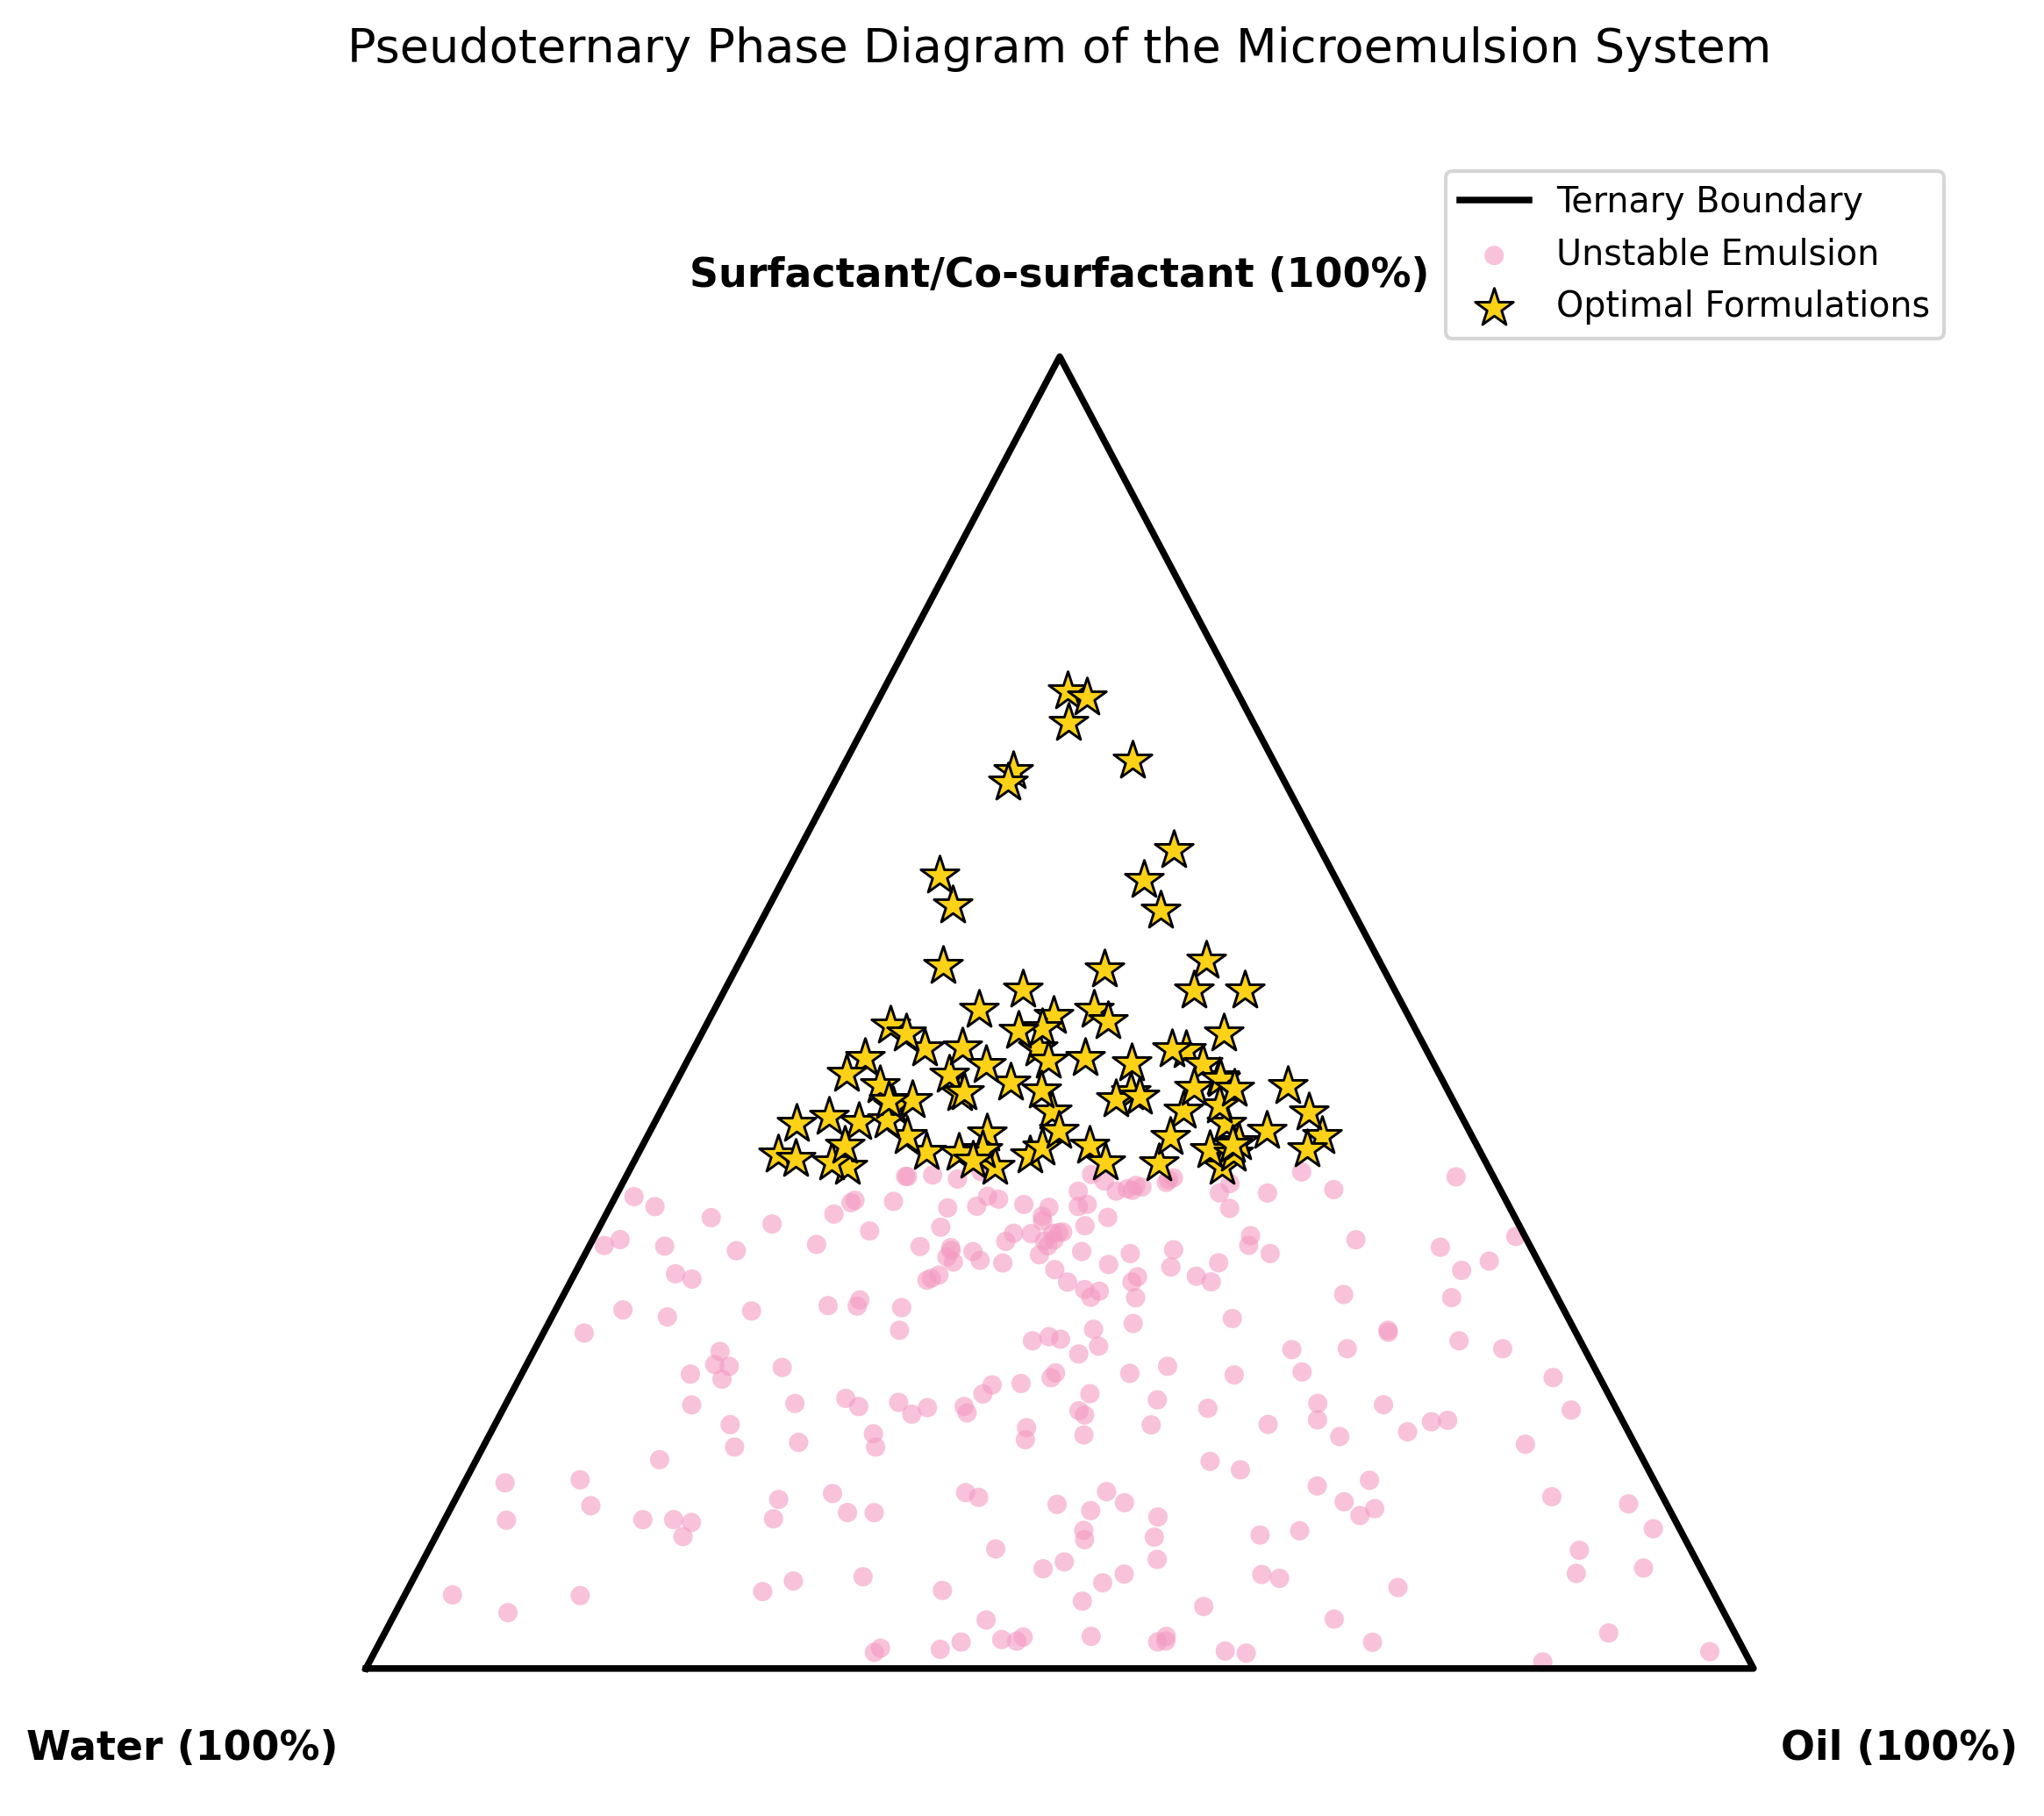

In [14]:
# @title
import numpy as np
import matplotlib.pyplot as plt

# 1. دالة تحويل النسب الثلاثية (Water, Oil, Surfactant) إلى إحداثيات (x, y) ديكارتية
def ternary_to_cartesian(w, o, s):
    """
    تحويل الإحداثيات الثلاثية إلى إحداثيات ثنائية الأبعاد (مثلث متساوي الأضلاع):
    - Water عند (0, 0)
    - Oil عند (1, 0)
    - Surfactant عند (0.5, sqrt(3)/2)
    """
    total = w + o + s
    w_norm = w / total
    o_norm = o / total
    s_norm = s / total

    x = o_norm + 0.5 * s_norm
    y = (np.sqrt(3) / 2) * s_norm
    return x, y

# 2. توليد بيانات تجريبية تحاكي النقاط في التقرير
np.random.seed(42)
n_samples = 400

# نسب عشوائية لمكونات النظام الثلاثي
w_rand = np.random.uniform(0, 100, n_samples)
o_rand = np.random.uniform(0, 100, n_samples)
s_rand = np.random.uniform(0, 100, n_samples)

totals = w_rand + o_rand + s_rand
w = (w_rand / totals) * 100
o = (o_rand / totals) * 100
s = (s_rand / totals) * 100

# تصنيف الحالات بناءً على تركيز السطحي (المستحلب غير المستقر مقابل الميكروإيمولشن المستقر)
unstable_mask = s < 38
optimal_mask = (s >= 38) & (s <= 85) & (w >= 10) & (o >= 10)

# 3. إعداد الرسم البياني
fig, ax = plt.subplots(figsize=(8, 7), dpi=300)

# رسم أضلاع المثلث الخارجي (Ternary Boundary)
corners = np.array([
    [0, 0],                         # Water (Bottom-Left)
    [1, 0],                         # Oil (Bottom-Right)
    [0.5, np.sqrt(3) / 2],          # Surfactant (Top Apex)
    [0, 0]                          # إغلاق المثلث
])
ax.plot(corners[:, 0], corners[:, 1], 'k-', lw=1.8, label='Ternary Boundary')

# رسم نقاط المستحلب غير المستقر (Unstable Emulsion - نقاط وردية)
x_unstable, y_unstable = ternary_to_cartesian(w[unstable_mask], o[unstable_mask], s[unstable_mask])
ax.scatter(x_unstable, y_unstable, c='#F49AC2', alpha=0.6, s=28, edgecolors='none', label='Unstable Emulsion')

# رسم نقاط التراكيب المثلى (Optimal Formulations - نجوم صفراء بإطار أسود)
x_opt, y_opt = ternary_to_cartesian(w[optimal_mask], o[optimal_mask], s[optimal_mask])
ax.scatter(x_opt, y_opt, c='#FCD116', marker='*', s=120, edgecolors='black', linewidths=0.7, label='Optimal Formulations')

# 4. إضافة تسميات الرؤوس (Vertices Labels)
ax.text(-0.02, -0.04, 'Water (100%)', fontsize=11, fontweight='bold', ha='right', va='top')
ax.text(1.02, -0.04, 'Oil (100%)', fontsize=11, fontweight='bold', ha='left', va='top')
ax.text(0.5, (np.sqrt(3) / 2) + 0.04, 'Surfactant/Co-surfactant (100%)',
        fontsize=11, fontweight='bold', ha='center', va='bottom')

# عنوان المخطط
ax.set_title("Pseudoternary Phase Diagram of the Microemulsion System", fontsize=13, pad=25)

# تخصيص مفتاح الخريطة (Legend)
ax.legend(loc='upper right', frameon=True, fontsize=9.5)

# ضبط حدود المحاور وإخفاء شبكة المحاور الديكارتية الافتراضية
ax.set_xlim(-0.15, 1.15)
ax.set_ylim(-0.08, 1.0)
ax.axis('off')

plt.tight_layout()
plt.show()
